In [1]:
import matplotlib.pyplot as plt
from platy5p1.data import read_sample_images
import pandas as pd
from pathlib import Path

## View images

It is possible to drag-and-drop samples to `napari` using `napari-ome-zarr` plugin or read and plot them in Python

In [2]:
data_dir = Path("../data")

In [3]:
samples = ["em", "stmhc_pl1", "stmhc_pl2", "stmhc_pl3", "stmhc_pl4", "stmhc_pl5"]

In [4]:
platy5plus1 = {}
for sample_name in samples:
    platy5plus1[sample_name], resolution = read_sample_images(data_dir, sample_name)
    print(sample_name, platy5plus1[sample_name]["raw"].shape)

no parent found for <ome_zarr.reader.Label object at 0x7ffd96ef4590>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd96e77b10>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd96f08e10>: None


no parent found for <ome_zarr.reader.Label object at 0x7ffd7ff795b0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd7ff79810>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd96e717f0>: None


em (1224, 1962, 1785)


no parent found for <ome_zarr.reader.Label object at 0x7ffd940e2ad0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd940e3df0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd7fd6fe50>: None


stmhc_pl1 (768, 2054, 1310)


...

stmhc_pl2 (733, 2040, 1430)


no parent found for <ome_zarr.reader.Label object at 0x7ffd7fd41390>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd7fd404b0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd7c373790>: None


stmhc_pl3 (748, 2070, 1440)


no parent found for <ome_zarr.reader.Label object at 0x7ffd7ff55850>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd7ff55fd0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ffd96f25020>: None


stmhc_pl4 (729, 1980, 1330)
stmhc_pl5 (706, 2050, 1370)


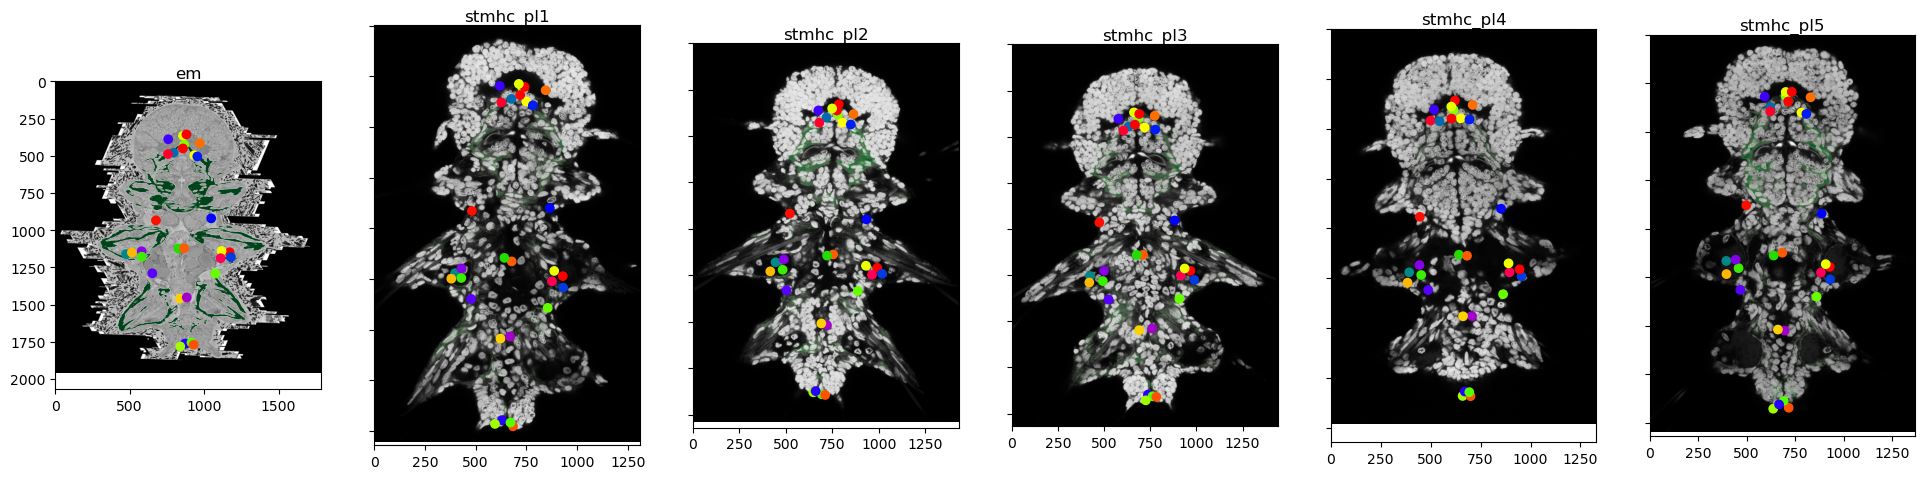

In [5]:
fig, axs = plt.subplots(1, 6, figsize=(24, 8), sharey="row")

for i, sample_name in enumerate(samples):
    images = platy5plus1[sample_name]
    sample_df = pd.read_csv(data_dir / f"{sample_name}.csv")

    ax = axs[i]
    
    ax.imshow(images["raw"][images["raw"].shape[0] // 2], cmap="gray")
    alpha = images["muscle"][images["muscle"].shape[0] // 2] / images["muscle"].max()
    ax.imshow(images["muscle"][images["muscle"].shape[0] // 2], cmap="Greens", alpha=alpha)
    ref_df = sample_df[sample_df["reg_gt"] != -1]
    ax.scatter(ref_df["x"], ref_df["y"], c=ref_df["reg_gt"], cmap="prism")
    ax.set_title(sample_name, va='top')
    ax.set_aspect("equal")

plt.show()
fig.tight_layout()
fig.savefig("dataset_view.png", dpi=300)

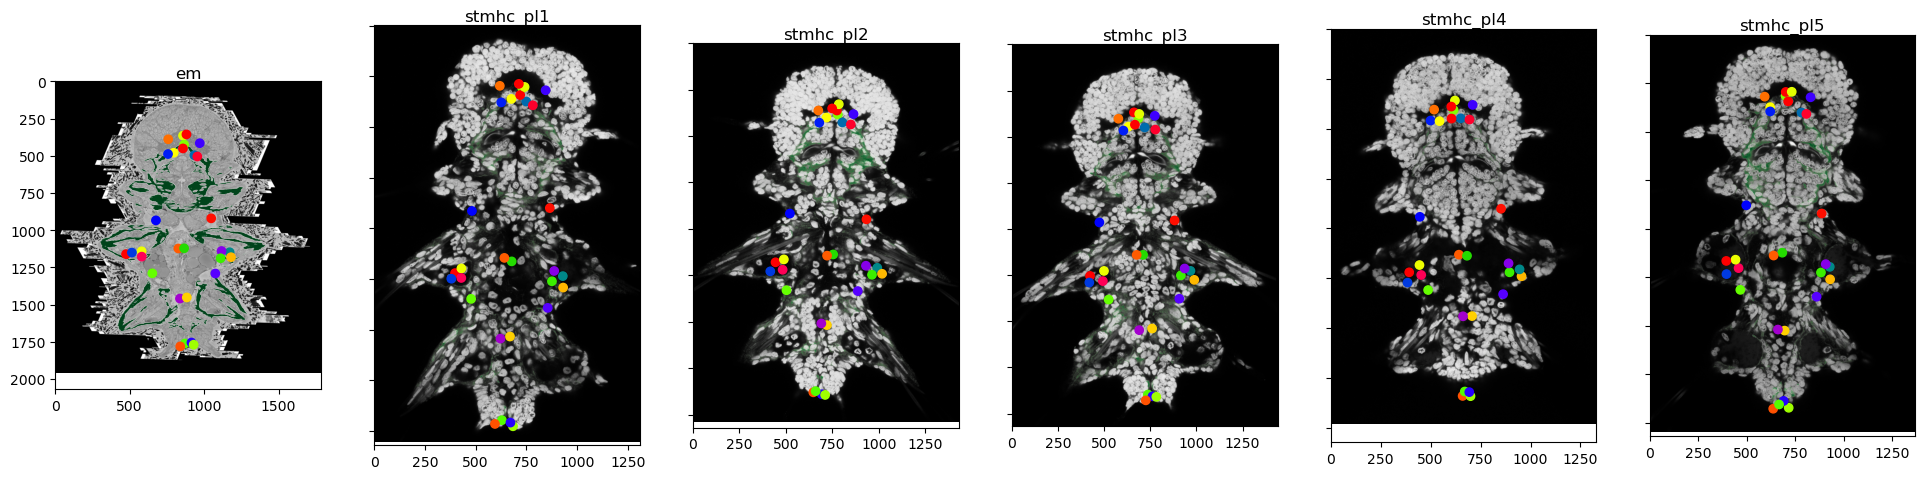

In [6]:
fig, axs = plt.subplots(1, 6, figsize=(24, 8), sharey="row")

for i, sample_name in enumerate(samples):
    images = platy5plus1[sample_name]
    sample_df = pd.read_csv(data_dir / f"{sample_name}.csv")

    ax = axs[i]
    
    ax.imshow(images["raw"][images["raw"].shape[0] // 2], cmap="gray", label="raw")
    alpha = images["muscle"][images["muscle"].shape[0] // 2] / images["muscle"].max()
    ax.imshow(images["muscle"][images["muscle"].shape[0] // 2], cmap="Greens", alpha=alpha, label="muscle")
    ref_df = sample_df[sample_df["reg_gt_reflected"] != -1]
    ax.scatter(ref_df["x"], ref_df["y"], c=ref_df["reg_gt_reflected"], cmap="prism")
    ax.set_title(sample_name, va='top')
    ax.set_aspect("equal")

plt.show()
fig.tight_layout()
fig.savefig("dataset_view_reflected.png", dpi=300)

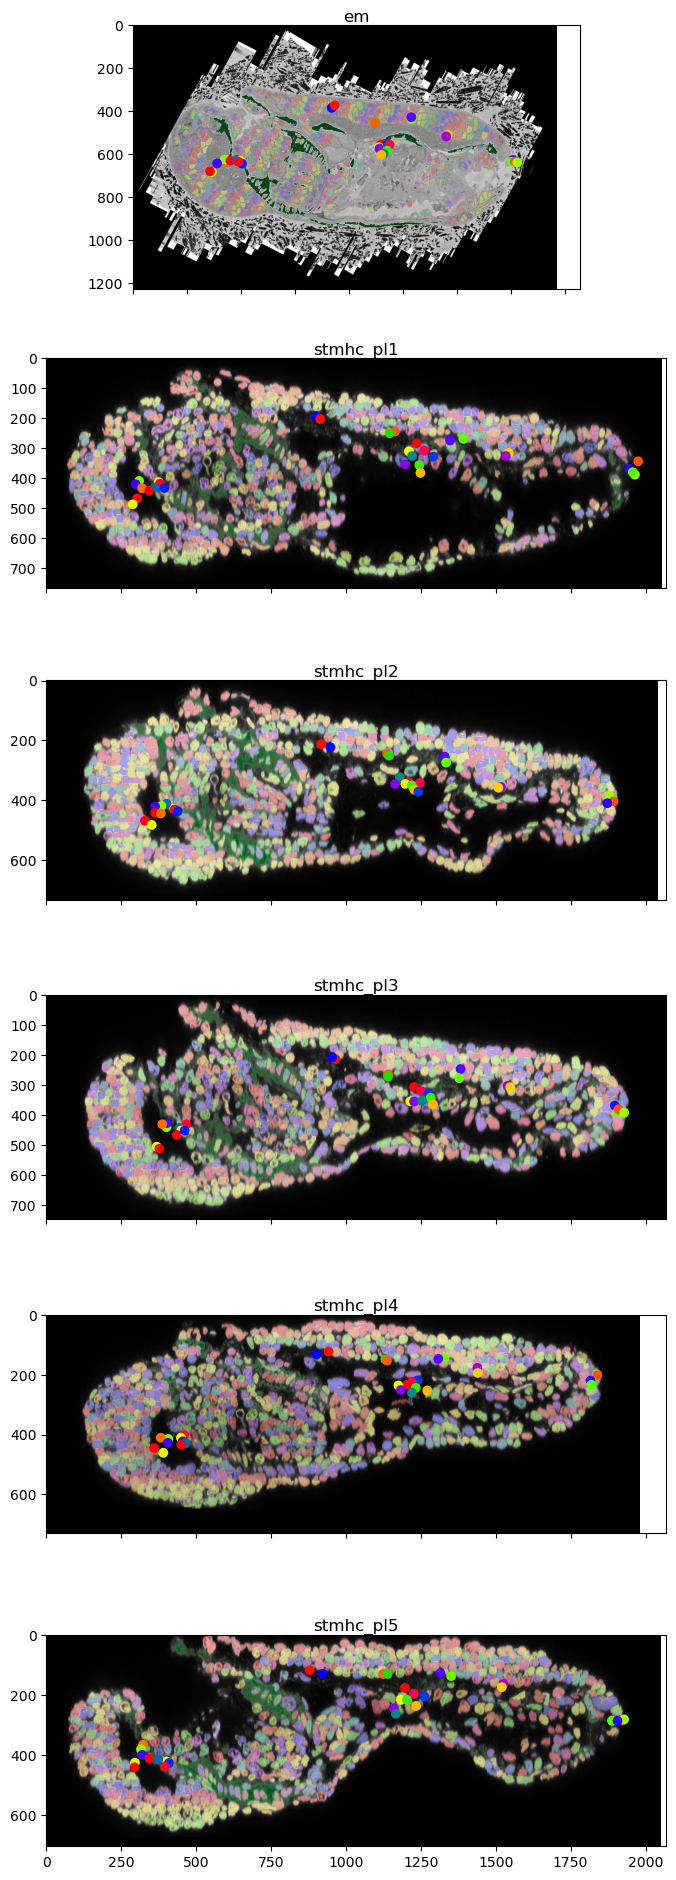

In [7]:
fig, axs = plt.subplots(6, 1, figsize=(8, 24), sharex="col")

for i, sample_name in enumerate(samples):
    images = platy5plus1[sample_name]
    sample_df = pd.read_csv(data_dir / f"{sample_name}.csv")

    ax = axs[i]
    
    ax.imshow(images["raw"][:, :, images["raw"].shape[2] // 2], cmap="gray")
    

    alpha = images["nuclei_segm"][:, : , images["nuclei_segm"].shape[2] // 2] > 0
    ax.imshow(images["nuclei_segm"][:, :, images["nuclei_segm"].shape[2] // 2], cmap="prism", alpha=0.3 * alpha)

    alpha = images["muscle"][:, :, images["muscle"].shape[2] // 2] / images["muscle"].max()
    ax.imshow(images["muscle"][:, :, images["muscle"].shape[2] // 2], cmap="Greens", alpha=alpha)

    
    ref_df = sample_df[sample_df["reg_gt"] != -1]
    ax.scatter(ref_df["y"], ref_df["z"], c=ref_df["reg_gt"], cmap="prism")
    ax.set_title(sample_name, va='top')
    ax.set_aspect("equal")

plt.show()
fig.tight_layout()
fig.savefig("dataset_view_zy.png", dpi=300)